In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder,FunctionTransformer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
import joblib, os

import seaborn as sns

In [3]:
df = pd.read_csv('../../hvstat_africa_data_v1.2.csv')

# number of rows and columns
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")


print("===============info========================")
df.info()
print("==============describe=====================")
df.describe()
print("==============head========================")
df.head()

Rows: 217487, Columns: 16
===============info========================
<class 'pandas.DataFrame'>
RangeIndex: 217487 entries, 0 to 217486
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   fnid                    217487 non-null  str    
 1   country                 217487 non-null  str    
 2   country_code            217487 non-null  str    
 3   admin_1                 217487 non-null  str    
 4   admin_2                 217487 non-null  str    
 5   product                 217487 non-null  str    
 6   season_name             217487 non-null  str    
 7   planting_year           217487 non-null  int64  
 8   planting_month          217487 non-null  int64  
 9   harvest_year            217487 non-null  int64  
 10  harvest_month           217487 non-null  int64  
 11  crop_production_system  217487 non-null  str    
 12  qc_flag                 217487 non-null  int64  
 13  area           

,fnid,country,country_code,admin_1,admin_2,product,season_name,planting_year,planting_month,harvest_year,harvest_month,crop_production_system,qc_flag,area,production,yield
0,AO2008A101,Angola,AO,Bengo,none,Banana,Main,2007,10,2008,4,All (PS),0,1364.0,19588.0,14.360704
1,AO2008A101,Angola,AO,Bengo,none,Banana,Main,2008,10,2009,4,All (PS),0,1547.0,24121.0,15.592114
2,AO2008A101,Angola,AO,Bengo,none,Banana,Main,2014,10,2015,4,All (PS),0,11513.0,331527.0,28.795883
3,AO2008A101,Angola,AO,Bengo,none,Banana,Main,2015,10,2016,4,All (PS),0,11513.0,331527.0,28.795883
4,AO2008A101,Angola,AO,Bengo,none,Banana,Main,2016,10,2017,4,All (PS),0,12628.7,351191.0,27.808959


In [4]:
d = df.dropna(subset=["yield", "area"])
d = d[(d["area"] > 0) & (d["yield"] > 0)]
d = d[d["qc_flag"] != 1]

n = d.groupby("product")["yield"].transform("count")
d = d[n >= 30]

med = d.groupby("product")["yield"].transform("median")
ratio = d["yield"] / med
clean_data = d[(ratio >= 0.05) & (ratio <= 20)].copy()

print(len(df), "->", len(clean_data))
print(clean_data["yield"].describe(percentiles=[.99, .999]))

217487 -> 198872
count    198872.000000
mean          3.393966
std           6.483144
min           0.010000
99%          29.727153
99.9%        60.000000
max         423.900000
Name: yield, dtype: float64


In [5]:
clean_data.info()

<class 'pandas.DataFrame'>
Index: 198872 entries, 0 to 217486
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   fnid                    198872 non-null  str    
 1   country                 198872 non-null  str    
 2   country_code            198872 non-null  str    
 3   admin_1                 198872 non-null  str    
 4   admin_2                 198872 non-null  str    
 5   product                 198872 non-null  str    
 6   season_name             198872 non-null  str    
 7   planting_year           198872 non-null  int64  
 8   planting_month          198872 non-null  int64  
 9   harvest_year            198872 non-null  int64  
 10  harvest_month           198872 non-null  int64  
 11  crop_production_system  198872 non-null  str    
 12  qc_flag                 198872 non-null  int64  
 13  area                    198872 non-null  float64
 14  production              198872 non-n

In [6]:

categorical_cols = ["country", "product", "season_name", "crop_production_system"]
numerical_cols = ["area", "planting_year", "planting_month", "harvest_month"]

#input features
X= clean_data[categorical_cols + numerical_cols].copy()
#since the area is highly skewed, i applied log transformation to it
X["area"] = np.log1p(X["area"])

#target variable
y= clean_data["yield"]

#dividing the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# using one hot encoding for categorical features and standard scaling for numerical features
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

# fitting the preprocess to the training data and transforming both training and testing data
X_train_p = preprocess.fit_transform(X_train)   
X_test_p  = preprocess.transform(X_test) 

print(X_train.shape, X_test.shape)
print(X_train_p.shape, X_test_p.shape)


(159097, 8) (39775, 8)
(159097, 181) (39775, 181)


In [7]:
#we are using the log transformation on the target variable to reduce the skewness and make it more normally distributed
y_train_log = np.log1p(y_train)
y_test_log  = np.log1p(y_test)

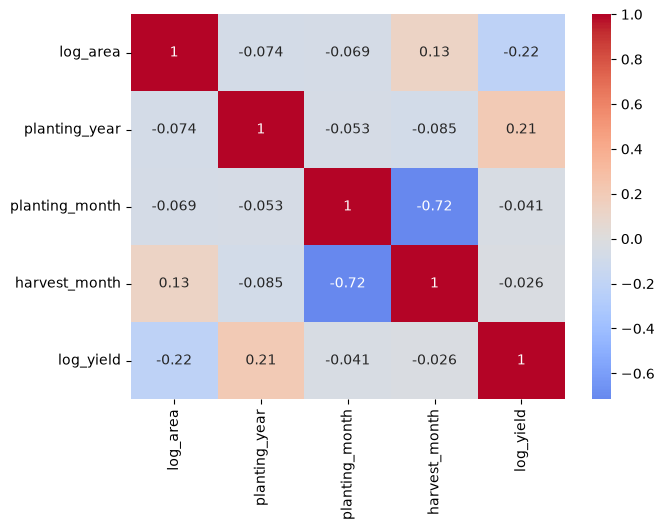

In [8]:
#plotting the distribution of the target variable before and after log transformation

eda = clean_data.copy()
eda["log_area"]  = np.log1p(eda["area"])
eda["log_yield"] = np.log1p(eda["yield"])

#plot1 

num = ["log_area", "planting_year", "planting_month", "harvest_month", "log_yield"]
plt.figure(figsize=(7, 5))
sns.heatmap(eda[num].corr(), annot=True, cmap="coolwarm", center=0)
plt.show()

The heatmap shows how each numeric feature correlates with log yield. The correlations that are weak: planting year is +0.21 and log area is -0.22, while planting month (-0.04) and harvest month (-0.03) are close to zero. The positive planting-year value could mean yields rise slightly over time, and the negative area value could mean larger areas have lower yield per hectare, though I haven’t tested the reasons for either. Planting month and harvest month are strongly related to each other (-0.72).

Decision: Since no numeric feature correlates strongly with yield, I expect a linear model on the numbers alone to struggle, so I will keep the categorical columns as features. Because the two month columns carry overlapping information

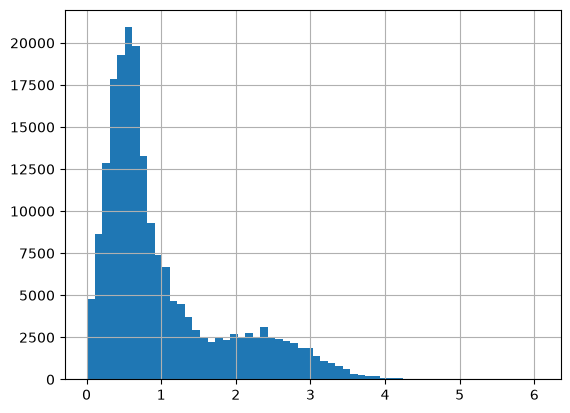

In [9]:
#plot2
eda["log_yield"].hist(bins=60)
plt.show()

The histogram shows the distribution of log yield. Most rows are concentrated at low values, with a peak of about 20,900 rows at a log yield of roughly 0.5 to 0.6. A long right tail extends to about 6, with a second smaller bump around 2 to 3. That bump is probably the high-yield crops (such as vegetables and sugarcane) rather than errors, since I already removed extreme values with the per-crop ratio rule.

Decision: Raw yield is heavily skewed, and a few very large values would dominate the squared error. So I train on log yield (log1p), which spreads the data more evenly, and I keep product as a feature because crops clearly form different groups.

In [10]:

rf = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf.fit(X_train_p, y_train_log)

names = preprocess.get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=names)

# add up the one-hot pieces back into the original column
def group_name(n):
    n = n.split("__", 1)[1]
    for c in categorical_cols:
        if n.startswith(c + "_"):
            return c
    return n

group = imp.groupby(group_name).sum()
print(group.sort_values(ascending=False))

product                   0.612302
season_name               0.137964
planting_month            0.097997
area                      0.040791
country                   0.039349
harvest_month             0.035703
planting_year             0.025417
crop_production_system    0.010476
dtype: float64


| Column | Action | Reason |
|---|---|---|
| `production` | Dropped | Gives the answer away because `yield = production / area`. |
| `yield` | Became the target | This is the value being predicted. |
| `fnid` | Dropped | An ID with no predictive meaning. |
| `country_code` | Dropped | Duplicates the information in `country`. |
| `admin_1`, `admin_2` | Dropped | Have many categories, including `"none"`, and add too many text fields for the app. |
| `harvest_year` | Dropped | Is almost always equal to `planting_year + 1`. |
| `qc_flag` | Dropped | A quality-control note that users would not know; rows with `qc_flag = 1` were removed. |


I measured feature importance with a random forest, grouping the one-hot columns back into their original feature. product is by far the most important (about 61%), followed by season_name (14%) and planting_month (10%). crop_production_system contributes the least (about 1%).

SGDRegressor and its loss curve

In [14]:
#Linear regression by gradient descent 
def train_SGD(learning_rate=0.001, alpha=0.0001, penalty="l2", epochs=30, seed=42):
    model = SGDRegressor(
        learning_rate="constant",   # keep the nudge size fixed, so eta0 is what we tune
        eta0=learning_rate,                  # learning rate
        alpha=alpha,                # regularization strength
        penalty=penalty,            # type of regularization to avoid overfitting 
        random_state=seed,
    )
    rng = np.random.default_rng(seed)
    n = X_train_p.shape[0]
    train_losses, test_losses = [], []

    for epoch in range(epochs):
        order = rng.permutation(n)              # shuffle rows every epoch
        model.partial_fit(X_train_p[order], y_train_log.values[order])   # ONE epoch
        train_losses.append(mean_squared_error(y_train_log, model.predict(X_train_p)))
        test_losses.append(mean_squared_error(y_test_log,  model.predict(X_test_p)))

    return model, train_losses, test_losses

sgd, train, test = train_SGD()


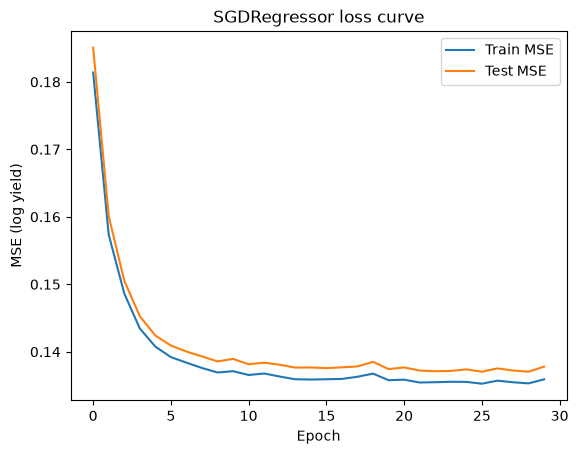

final train MSE: 0.13591113180216927  final test MSE: 0.13778992807906448


In [15]:
# plotting the training and testing loss curves
plt.plot(train, label="Train MSE")
plt.plot(test, label="Test MSE")
plt.xlabel("Epoch"); plt.ylabel("MSE (log yield)")
plt.title("SGDRegressor loss curve")
plt.legend(); plt.show()

print("final train MSE:", train[-1], " final test MSE:", test[-1])

In [16]:
#calculate function

def calculate(name,model):
    tr = mean_squared_error(y_train_log, model.predict(X_train_p))
    te = mean_squared_error(y_test_log,  model.predict(X_test_p))
    print(f"{name:25s} train MSE {tr:.4f}   test MSE {te:.4f}")
    return tr, te

In [17]:
#Linear regression, closed form .it calculates the optimal model weights directly in a single mathematical step

def train_Linear():
    linear= LinearRegression().fit(X_train_p, y_train_log)
    calculate('LinearRegression ',linear)

print(train_Linear())

LinearRegression          train MSE 0.1345   test MSE 0.1362
None


In [18]:
#decision tree regression

def train_DecisionTree(max_depth=10, random_state=42):
    for depth in [None,10,20]:
        tree= DecisionTreeRegressor(max_depth=depth, random_state=random_state).fit(X_train_p, y_train_log)
        calculate(f'DecisionTree max_depth={depth}',tree)

print(train_DecisionTree())

DecisionTree max_depth=None train MSE 0.0011   test MSE 0.1294
DecisionTree max_depth=10 train MSE 0.2365   test MSE 0.2428
DecisionTree max_depth=20 train MSE 0.0827   test MSE 0.1245
None


In [19]:
#random forest regression

def train_RandomForest(n_estimators=50, max_depth=20, random_state=42):
    rf = RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, n_jobs=-1, random_state=random_state)
    rf.fit(X_train_p, y_train_log)
    calculate(f'RandomForest n_estimators={n_estimators} max_depth={max_depth}', rf)

print(train_RandomForest())

RandomForest n_estimators=50 max_depth=20 train MSE 0.0756   test MSE 0.1025
None


In [20]:
#experiment with different min_sample leaf values for Random Forest Regressor to see if we can readuce size
results = {}
for leaf in [1, 5, 10]:
    rf = RandomForestRegressor(n_estimators=50, max_depth=20,
                               min_samples_leaf=leaf, n_jobs=-1, random_state=42)
    rf.fit(X_train_p, y_train_log)
    tr = mean_squared_error(y_train_log, rf.predict(X_train_p))
    te = mean_squared_error(y_test_log,  rf.predict(X_test_p))
    results[leaf] = (tr, te, rf)
    print(f"min_samples_leaf={leaf:2d}  train {tr:.4f}  test {te:.4f}")

min_samples_leaf= 1  train 0.0756  test 0.1025
min_samples_leaf= 5  train 0.0871  test 0.1012
min_samples_leaf=10  train 0.0930  test 0.1032


In [21]:
comparison = pd.DataFrame({
    "Model": ["SGDRegressor (eta0=0.001, alpha=0.0001, 30 epochs)",
              "LinearRegression (closed form)",
              "DecisionTree (max_depth=20)",
              "RandomForest (50 trees, max_depth=20, min_samples_leaf=5)"],
    "Train MSE": [0.1359, 0.1345, 0.0827, 0.0871],
    "Test MSE":  [0.1378, 0.1362, 0.1246, 0.1012],
}).sort_values("Test MSE").reset_index(drop=True)

print(comparison)
print("Best model (lowest test MSE):", comparison.iloc[0]["Model"])

                                               Model  Train MSE  Test MSE
0  RandomForest (50 trees, max_depth=20, min_samp...     0.0871    0.1012
1                        DecisionTree (max_depth=20)     0.0827    0.1246
2                     LinearRegression (closed form)     0.1345    0.1362
3  SGDRegressor (eta0=0.001, alpha=0.0001, 30 epo...     0.1359    0.1378
Best model (lowest test MSE): RandomForest (50 trees, max_depth=20, min_samples_leaf=5)


The best model is the Random Forest because it has the lowest test MSE (0.1012), and test error is the criterion since it measures performance on unseen data. All MSE values are on the log-yield scale.

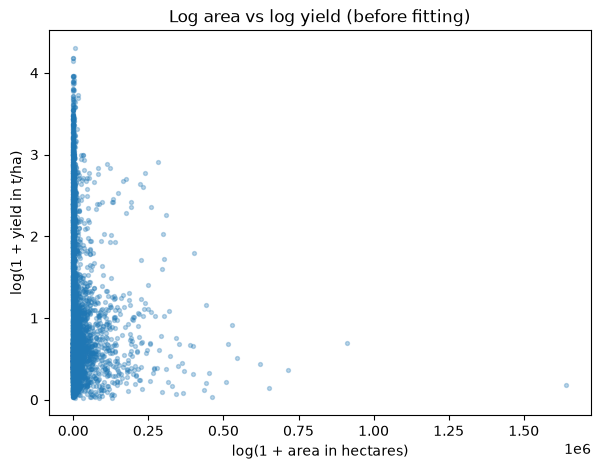

In [22]:
#Scatter plot, before.

# a random sample of 5000 training points, so the plot isn't an unreadable blob
s = X_train.sample(5000, random_state=42)
xs = s["area"]
ys = y_train_log.loc[s.index]

plt.figure(figsize=(7, 5))
plt.scatter(xs, ys, alpha=0.3, s=8)
plt.xlabel("log(1 + area in hectares)")
plt.ylabel("log(1 + yield in t/ha)")
plt.title("Log area vs log yield (before fitting)")
plt.show()



The  scatter plot above shows log area (x-axis) against log yield (y-axis) for a sample of 5,000 training rows. The points form a wide cloud with no clear pattern, with a dense band at low log yield (around 0.5) and a smaller scattered group at higher values (2 to 4). This matches the weak correlation of about -0.2, so area alone is a poor predictor of yield.

Decision: Because no single numeric feature separates the points, I will use the categorical features, especially crop, and compare linear models against tree-based models that can capture combinations of features.which was shown to produce a lower MSE than the linear models

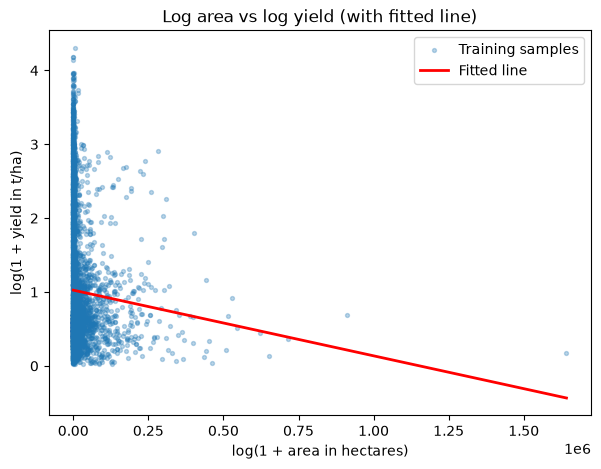

slope: -8.890827892420308e-07  intercept: 1.0252098589759089


In [23]:
#Scatter plot, after (same points + fitted line)
one = LinearRegression().fit(X_train[["area"]], y_train_log)   # one feature only
x_line = pd.DataFrame({"area": np.linspace(xs.min(), xs.max(), 100)})

plt.figure(figsize=(7, 5))
plt.scatter(xs, ys, alpha=0.3, s=8, label="Training samples")
plt.plot(x_line["area"], one.predict(x_line), color="red", linewidth=2, label="Fitted line")
plt.xlabel("log(1 + area in hectares)")
plt.ylabel("log(1 + yield in t/ha)")
plt.title("Log area vs log yield (with fitted line)")
plt.legend()
plt.show()

print("slope:", one.coef_[0], " intercept:", one.intercept_)

Also the scatter plot above adds the line from a linear regression trained on log area only. The line has a slight negative slope (about -0.06, replace with your printed value), which suggests that larger areas have slightly lower yield per hectare on average. The points are widely spread around the line, and the line runs between the two groups of points without fitting either well, so area explains only a small part of the variation.

Decision: A straight-line model using one numeric feature was enough for this problem. The model needs the crop type and other categorical features, which supported comparing it with tree and forest models.

I used the log values of area and yield helps to normalize the data and make it more suitable for linear modeling. Log transformations make highly skewed area and yield data easier to visualize and model by reducing the influence of extreme values. 
They focus on proportional differences rather than absolute differences and prevent MSE from being dominated by a few unusually large observations. 
We use `log1p(x)` safely near zero and convert predictions back to real units with `expm1`; however, errors on the log scale represent multiplicative factors rather than tonnes per hectare.

In [25]:
#making the preposesor so all the features are transformed in the same way as they were for the best model, so that we can use the saved model for predictions on new data

other_num = ["planting_year", "planting_month", "harvest_month"]
feature_cols = categorical_cols + ["area"] + other_num

# RAW features (area NOT logged here) and RAW yield
X = clean_data[feature_cols]
y = clean_data["yield"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

preprocess = ColumnTransformer([
    ("area", Pipeline([("log", FunctionTransformer(np.log1p)),
                       ("scale", StandardScaler())]), ["area"]),
    ("numerical", StandardScaler(), other_num),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

best_model = Pipeline([
    ("prep", preprocess),
    ("rf", TransformedTargetRegressor(
        regressor=RandomForestRegressor(n_estimators=50, max_depth=20,
                                        min_samples_leaf=5, n_jobs=-1, random_state=42),
        func=np.log1p, inverse_func=np.expm1)),
])

best_model.fit(X_train, y_train)

# check: same log-scale MSE as in the comparison table
pred = best_model.predict(X_test)
print("Test MSE (log scale):", mean_squared_error(np.log1p(y_test), np.log1p(pred)))

# save
os.makedirs("../API", exist_ok=True)
joblib.dump(best_model, "../API/best_model.pkl", compress=3)
print("Saved, size (MB):", os.path.getsize("../API/best_model.pkl") / 1e6)

Test MSE (log scale): 0.1011944753195427
Saved, size (MB): 7.951548


In [26]:
def predict_test_row(row_index=0, model_path="../API/best_model.pkl"):
    model = joblib.load(model_path)
    row = X_test.iloc[[row_index]]          # double brackets keep it a one-row table
    predicted = model.predict(row)[0]       # already in tonnes per hectare
    actual = y_test.iloc[row_index]
    print("Input row:", row.to_dict("records")[0])
    print(f"Predicted yield: {predicted:.2f} t/ha")
    print(f"Actual yield:    {actual:.2f} t/ha")
    return predicted

predict_test_row(0)

Input row: {'country': 'Benin', 'product': 'Onions', 'season_name': 'Main', 'crop_production_system': 'All (PS)', 'area': 4.0, 'planting_year': 2020, 'planting_month': 3, 'harvest_month': 10}
Predicted yield: 4.94 t/ha
Actual yield:    5.25 t/ha


np.float64(4.937196653036602)

In [27]:
cols = feature_cols + ["yield"]
clean_data[cols].to_csv("../API/training_data.csv.gz", index=False)
print(clean_data[cols].shape)
print(clean_data[cols].columns.tolist())

(198872, 9)
['country', 'product', 'season_name', 'crop_production_system', 'area', 'planting_year', 'planting_month', 'harvest_month', 'yield']


In [29]:
sample = clean_data[feature_cols + ["yield"]].sample(200, random_state=1)
sample.to_csv("new_data_sample.csv", index=False)
print(sample.shape)

(200, 9)
